# Partie I - Analyse des données et analyse univariée

> **Avant le clustering.** Un clustering calcule des distances entre
> liaisons. Une valeur impossible, un zéro qui cache un manquant ou une colonne mal typée
> déplacent ces distances **sans aucun message d'erreur**. La session 3 du cours le résume :
> *the mechanism matters more than the rate*.

**Objectifs**
1. Vérifier le **typage** : type informatique vs type statistique de chaque colonne.
2. Recenser les **valeurs impossibles ou suspectes** (négatifs, incohérences logiques, zéros déguisés).
3. Prendre et **documenter des décisions** (elles alimentent la datasheet).
4. Faire l'**analyse univariée** complète : quantitative, qualitative, temporelle.

In [1]:
# ── Setup ─────────────────────────────────────────────────────────────────────
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.float_format", "{:.4f}".format)
pd.set_option("display.max_columns", 40)
SEED = 42  # reproducibility (course rule)

RAW_PATH = Path("../data/raw/regularite-mensuelle-tgv-aqst.csv")

In [2]:
raw = pd.read_csv(RAW_PATH, sep=";", encoding="utf-8-sig")
print(raw.shape)
raw.head(3)

(12907, 26)


,Date,Service,Gare de départ,Gare d'arrivée,Durée moyenne du trajet,Nombre de circulations prévues,Nombre de trains annulés,Commentaire annulations,Nombre de trains en retard au départ,Retard moyen des trains en retard au départ,Retard moyen de tous les trains au départ,Commentaire retards au départ,Nombre de trains en retard à l'arrivée,Retard moyen des trains en retard à l'arrivée,Retard moyen de tous les trains à l'arrivée,Commentaire retards à l'arrivée,Nombre trains en retard > 15min,Retard moyen trains en retard > 15 (si liaison concurrencée par vol),Nombre trains en retard > 30min,Nombre trains en retard > 60min,Prct retard pour causes externes,Prct retard pour cause infrastructure,Prct retard pour cause gestion trafic,Prct retard pour cause matériel roulant,Prct retard pour cause gestion en gare et réutilisation de matériel,"Prct retard pour cause prise en compte voyageurs (affluence, gestions PSH, correspondances)"
0,2018-01,National,BORDEAUX ST JEAN,PARIS MONTPARNASSE,141,870,5,NaN,289,11.2478,3.6932,NaN,147,28.4367,6.5111,NaN,110,6.5111,44,8,36.1345,31.0924,10.9244,15.9664,5.0420,0.8403
1,2018-01,National,LE MANS,PARIS MONTPARNASSE,56,406,1,NaN,213,8.4800,4.5671,NaN,105,18.0490,5.3635,"Ce mois-ci, l'OD a été touchée par les inciden...",32,5.3635,9,4,20.0000,35.0000,16.6667,16.6667,8.3333,3.3333
2,2018-01,National,PARIS MONTPARNASSE,LA ROCHELLE VILLE,166,226,0,NaN,21,6.2397,0.2863,NaN,19,24.7368,2.9381,NaN,11,2.9381,6,1,22.2222,27.7778,16.6667,16.6667,5.5556,11.1111


## I.2 Audit du typage : type informatique vs type statistique

Session 1 : *types in statistics ≠ types in programming*. Pandas devine un type de stockage
(`int64`, `float64`, `object`/`str`). Nous, on a besoin du **type statistique** pour savoir
quelles opérations ont un sens :

| Type statistique | Opérations légitimes | Exemple ici |
|---|---|---|
| Nominal | comptage, mode | gare, service |
| Ordinal / temporel | tri, comparaisons, écarts | mois |
| Comptage (entier ≥ 0) | sommes, ratios | trains prévus, annulés, en retard |
| Continu | moyenne, quantiles | durée, retard moyen |
| Proportion / composition | moyenne **pondérée** uniquement, somme = 100 | % de causes |
| Texte libre | lecture qualitative | commentaires |

In [3]:
EXPECTED = {
    "Date": "temporal (month)", "Service": "nominal", "Gare de départ": "nominal",
    "Gare d'arrivée": "nominal", "Durée moyenne du trajet": "continuous (min)",
    "Commentaire annulations": "free text", "Commentaire retards au départ": "free text",
    "Commentaire retards à l'arrivée": "free text",
}
for col in raw.columns:
    if col.startswith(("Nombre", )):
        EXPECTED[col] = "count (int >= 0)"
    elif col.startswith("Prct"):
        EXPECTED[col] = "proportion (0-100)"
    elif col.startswith("Retard moyen"):
        EXPECTED[col] = "continuous (min)"

audit = pd.DataFrame({
    "pandas_dtype": raw.dtypes.astype(str),
    "expected_type": pd.Series(EXPECTED),
    "n_unique": raw.nunique(),
    "pct_missing": raw.isna().mean().round(4),
    "example": raw.iloc[0],
})
audit

,pandas_dtype,expected_type,n_unique,pct_missing,example
Commentaire annulations,float64,free text,0,1.0000,NaN
Commentaire retards au départ,float64,free text,0,1.0000,NaN
Commentaire retards à l'arrivée,str,free text,302,0.9459,NaN
Date,str,temporal (month),105,0.0000,2018-01
Durée moyenne du trajet,int64,continuous (min),411,0.0000,141
Gare d'arrivée,str,nominal,59,0.0000,PARIS MONTPARNASSE
Gare de départ,str,nominal,59,0.0000,BORDEAUX ST JEAN
Nombre de circulations prévues,int64,count (int >= 0),908,0.0000,870
Nombre de trains annulés,int64,count (int >= 0),192,0.0000,5
Nombre de trains en retard au départ,int64,count (int >= 0),460,0.0000,289


**À lire dans ce tableau**
- `Date` est stockée en texte : on ne peut ni trier chronologiquement de façon sûre, ni extraire
  le mois calendaire. → conversion en `Period[M]`.
- Une colonne de **comptage** stockée en `float64` signale souvent des `NaN` ou des valeurs
  non entières ; une colonne numérique en `object`/`str` signale du texte parasite (virgule
  décimale, espace, « ND »…). La cellule suivante le teste.
- Les commentaires sont quasi vides : inutilisables comme variables.

In [4]:
# Which numeric-looking columns fail a strict numeric conversion?
num_like = [c for c, t in EXPECTED.items() if t.startswith(("count", "continuous", "proportion"))]
for col in num_like:
    converted = pd.to_numeric(raw[col], errors="coerce")
    new_nan = converted.isna().sum() - raw[col].isna().sum()
    non_int = 0
    if EXPECTED[col].startswith("count"):
        non_int = ((converted.dropna() % 1) != 0).sum()
    if new_nan or non_int:
        print(f"{col!r}: {new_nan} values not numeric, {non_int} non-integer counts")
print("Conversion check done.")

Conversion check done.


## I.3 Renommage et typage

On renomme en `snake_case` (plus pratique) et on applique les types attendus. **Aucune
correction de valeur ici** : on corrige le *contenant*, pas le *contenu*.

In [5]:
COL_MAP = {
    "Date": "date", "Service": "service", "Gare de départ": "departure",
    "Gare d'arrivée": "arrival", "Durée moyenne du trajet": "trip_duration_min",
    "Nombre de circulations prévues": "trains_planned",
    "Nombre de trains annulés": "trains_cancelled",
    "Commentaire annulations": "comment_cancellations",
    "Nombre de trains en retard au départ": "late_departure",
    "Retard moyen des trains en retard au départ": "mean_delay_late_dep",
    "Retard moyen de tous les trains au départ": "mean_delay_all_dep",
    "Commentaire retards au départ": "comment_departure",
    "Nombre de trains en retard à l'arrivée": "late_arrival",
    "Retard moyen des trains en retard à l'arrivée": "mean_delay_late_arr",
    "Retard moyen de tous les trains à l'arrivée": "mean_delay_all_arr",
    "Commentaire retards à l'arrivée": "comment_arrival",
    "Nombre trains en retard > 15min": "late_15min",
    "Retard moyen trains en retard > 15 (si liaison concurrencée par vol)": "delay_15_flight_unclear",
    "Nombre trains en retard > 30min": "late_30min",
    "Nombre trains en retard > 60min": "late_60min",
    "Prct retard pour causes externes": "pct_cause_external",
    "Prct retard pour cause infrastructure": "pct_cause_infra",
    "Prct retard pour cause gestion trafic": "pct_cause_traffic",
    "Prct retard pour cause matériel roulant": "pct_cause_rolling_stock",
    "Prct retard pour cause gestion en gare et réutilisation de matériel": "pct_cause_station_mgmt",
    "Prct retard pour cause prise en compte voyageurs "
    "(affluence, gestions PSH, correspondances)": "pct_cause_passengers",
}
COUNT_COLS = ["trains_planned", "trains_cancelled", "late_departure", "late_arrival",
              "late_15min", "late_30min", "late_60min"]
DELAY_COLS = ["mean_delay_late_dep", "mean_delay_all_dep", "mean_delay_late_arr", "mean_delay_all_arr"]
PCT_COLS = [c for c in COL_MAP.values() if c.startswith("pct_cause_")]

df = raw.rename(columns=COL_MAP)
df["date"] = pd.to_datetime(df["date"].astype(str)).dt.to_period("M")
for col in ("service", "departure", "arrival"):
    df[col] = df[col].astype(str).str.strip().str.upper()
num_cols = ["trip_duration_min", *COUNT_COLS, *DELAY_COLS, *PCT_COLS, "delay_15_flight_unclear"]
df[num_cols] = df[num_cols].apply(pd.to_numeric, errors="coerce")
df["route"] = df["departure"] + " → " + df["arrival"]
df["trains_run"] = df["trains_planned"] - df["trains_cancelled"]   # NOT clipped on purpose
df.dtypes

date                       period[M]
service                          str
departure                        str
arrival                          str
trip_duration_min              int64
trains_planned                 int64
trains_cancelled               int64
comment_cancellations        float64
late_departure                 int64
mean_delay_late_dep          float64
mean_delay_all_dep           float64
comment_departure            float64
late_arrival                   int64
mean_delay_late_arr          float64
mean_delay_all_arr           float64
comment_arrival                  str
late_15min                     int64
delay_15_flight_unclear      float64
late_30min                     int64
late_60min                     int64
pct_cause_external           float64
pct_cause_infra              float64
pct_cause_traffic            float64
pct_cause_rolling_stock      float64
pct_cause_station_mgmt       float64
pct_cause_passengers         float64
route                            str
t

⚠️ **Pourquoi on ne fait pas `.clip(lower=0)` sur `trains_run`** (ce que faisait la v1) :
`clip` transforme une valeur *impossible* (−3 trains circulés) en une valeur *plausible* (0
train circulé, soit 100 % d'annulation). L'erreur disparaît de la vue mais reste dans les
calculs. Une valeur impossible doit être **signalée**, puis traitée par une décision explicite.

## I.4 Clé et doublons

Une ligne doit correspondre à un unique triplet *(mois, service, liaison)*. Sinon, toute
somme par liaison compte des trains deux fois.

In [6]:
key = ["date", "service", "departure", "arrival"]
dup = df.duplicated(subset=key, keep=False)
print(f"Duplicated keys: {dup.sum()} rows")
print(f"Routes present in several services: "
      f"{(df.groupby('route')['service'].nunique() > 1).sum()}")
df[dup].sort_values(key).head(10)

Duplicated keys: 0 rows
Routes present in several services: 16


,date,service,departure,arrival,trip_duration_min,trains_planned,trains_cancelled,comment_cancellations,late_departure,mean_delay_late_dep,mean_delay_all_dep,comment_departure,late_arrival,mean_delay_late_arr,mean_delay_all_arr,comment_arrival,late_15min,delay_15_flight_unclear,late_30min,late_60min,pct_cause_external,pct_cause_infra,pct_cause_traffic,pct_cause_rolling_stock,pct_cause_station_mgmt,pct_cause_passengers,route,trains_run


## I.5 Audit des valeurs impossibles ou suspectes

On écrit chaque règle métier comme un test vectorisé. Trois familles :

- **Impossible** : contredit la définition (un comptage négatif, plus d'annulés que de prévus).
- **Incohérence logique** : contredit une autre colonne. Exemple clé : le seuil « composite »
  de la colonne *en retard à l'arrivée* vaut 5, 10 ou 15 min selon la durée, donc **tout train
  en retard de plus de 15 min est aussi compté « en retard »** :
  $L^{15} \le L^{\text{arr}}$. De même $L^{60} \le L^{30} \le L^{15}$.
- **Manquant déguisé** (session 3 : *a 0 can be a disguised missing value*) : un « retard moyen
  des trains en retard » égal à 0 quand **aucun** train n'est en retard n'est pas un retard nul,
  c'est une valeur **qui n'existe pas**.

In [7]:
pct_sum = df[PCT_COLS].sum(axis=1)
RULES = {
    # Impossible values
    **{f"{c} < 0": df[c] < 0 for c in COUNT_COLS},
    "trains_cancelled > trains_planned": df["trains_cancelled"] > df["trains_planned"],
    "trip_duration_min <= 0": df["trip_duration_min"] <= 0,
    "mean_delay_late_arr < 0": df["mean_delay_late_arr"] < 0,
    "pct outside [0, 100]": ((df[PCT_COLS] < 0) | (df[PCT_COLS] > 100)).any(axis=1),
    # Logical inconsistencies
    "late_arrival > trains_run": df["late_arrival"] > df["trains_run"],
    "late_departure > trains_run": df["late_departure"] > df["trains_run"],
    "late_15min > late_arrival": df["late_15min"] > df["late_arrival"],
    "late_30min > late_15min": df["late_30min"] > df["late_15min"],
    "late_60min > late_30min": df["late_60min"] > df["late_30min"],
    "pct sum != 100 while late > 0": (df["late_arrival"] > 0) & ((pct_sum - 100).abs() > 1),
    # Disguised missing values
    "mean_delay_late_arr == 0 while late == 0": (df["late_arrival"] == 0) & (df["mean_delay_late_arr"] == 0),
    "pct sum == 0 while late == 0": (df["late_arrival"] == 0) & (pct_sum == 0),
    "mean_delay_late_arr == 0 while late > 0": (df["late_arrival"] > 0) & (df["mean_delay_late_arr"] == 0),
    # Legitimate but surprising
    "mean_delay_all_arr < 0": df["mean_delay_all_arr"] < 0,
    "mean_delay_all_dep < 0": df["mean_delay_all_dep"] < 0,
    "trains_run == 0 (fully cancelled)": df["trains_run"] == 0,
}
rule_table = pd.DataFrame({
    "n_rows": {name: int(mask.sum()) for name, mask in RULES.items()},
    "pct_rows": {name: mask.mean() for name, mask in RULES.items()},
}).sort_values("n_rows", ascending=False)
rule_table

,n_rows,pct_rows
late_60min > late_30min,354,0.0274
mean_delay_late_arr == 0 while late == 0,192,0.0149
pct sum == 0 while late == 0,192,0.0149
mean_delay_all_dep < 0,170,0.0132
mean_delay_all_arr < 0,122,0.0095
pct sum != 100 while late > 0,89,0.0069
trip_duration_min <= 0,73,0.0057
late_departure > trains_run,64,0.0050
trains_cancelled > trains_planned,63,0.0049
late_arrival > trains_run,63,0.0049


In [8]:
# Where are the impossible cancellations? Concentrated or scattered?
bad = df[RULES["trains_cancelled > trains_planned"]]
print(f"{len(bad)} rows, {bad['route'].nunique()} routes, {bad['date'].nunique()} months")
display(bad["date"].astype(str).value_counts().head(10).rename("rows per month"))
bad[["date", "route", "trains_planned", "trains_cancelled", "trains_run"]].head(10)

63 rows, 52 routes, 3 months


date
2020-04    50
2020-05     9
2020-06     4
Name: rows per month, dtype: int64

,date,route,trains_planned,trains_cancelled,trains_run
3406,2020-04,PARIS MONTPARNASSE → ST MALO,0,8,-8
3407,2020-04,PARIS MONTPARNASSE → TOURS,0,9,-9
3409,2020-04,NANTES → STRASBOURG,0,2,-2
3411,2020-04,PARIS NORD → DOUAI,0,12,-12
3412,2020-04,DUNKERQUE → PARIS NORD,0,15,-15
3414,2020-04,MARSEILLE ST CHARLES → TOURCOING,0,1,-1
3415,2020-04,LYON PART DIEU → MARNE LA VALLEE,0,19,-19
3416,2020-04,MARNE LA VALLEE → MARSEILLE ST CHARLES,0,14,-14
3417,2020-04,MARSEILLE ST CHARLES → MARNE LA VALLEE,0,13,-13
3418,2020-04,PARIS LYON → AIX EN PROVENCE TGV,0,17,-17


In [9]:
# Negative "mean delay of ALL trains": how negative? (early arrivals on average)
neg = df.loc[df["mean_delay_all_arr"] < 0, "mean_delay_all_arr"]
print(neg.describe())

count    122.0000
mean     -12.9090
std       52.2687
min     -472.6389
25%       -1.7600
50%       -0.6933
75%       -0.3203
max       -0.0006
Name: mean_delay_all_arr, dtype: float64


## I.6 Décisions et justification

Une décision se juge à trois questions : **quelle est la nature de l'anomalie ? que fait chaque
option à l'analyse ? peut-on vérifier que le résultat n'en dépend pas ?** Les décisions
ci-dessous sont celles du « bloc commun » des notebooks 01 à 04.

| # | Anomalie | Nature | Décision | Pourquoi pas une autre option |
|---|---|---|---|---|
| D1 | Comptage < 0 | Impossible | → `NaN`, ligne exclue des calculs | Remplacer par 0 ou par la valeur absolue invente une donnée |
| D2 | Annulés > prévus | Impossible | Ligne **signalée et exclue** (≈ 0,5 % des lignes) | `clip(0)` transforme l'erreur en « 100 % annulé » ; corriger « annulés = prévus » invente une donnée |
| D3 | Retard moyen des trains en retard = 0 et causes = 0 quand aucun train n'est en retard | Manquant déguisé (valeur indéfinie) | → `NaN` | Garder 0 tire les moyennes vers le bas et fait croire qu'un retard « nul » existe |
| D4 | Commentaires vides ; colonne « > 15 (si liaison concurrencée par vol) » non documentée (ses valeurs sont < 15 min, incompatible avec son nom) | Inexploitable / définition floue | Colonnes supprimées | Utiliser une variable qu'on ne sait pas définir rend l'analyse indéfendable |
| D5 | Retard moyen de **tous** les trains < 0 | **Légitime** : les trains en avance comptent négativement | Conservé | Le supprimer biaiserait les liaisons ponctuelles vers le haut |
| D6 | Liaisons entièrement annulées un mois (`trains_run == 0`) | Légitime | Conservées pour le taux d'annulation, exclues des taux de retard du mois (division par 0) | Les retirer cacherait précisément les annulations |

**Contrôle de robustesse à prévoir** : refaire le clustering en incluant les lignes D2 avec
`trains_cancelled = trains_planned`. Si les profils ne bougent pas (ARI ≈ 1), la décision
n'influence pas la conclusion, et on peut l'écrire.

**À vérifier sur tes sorties** : si la règle `late_15min > late_arrival` a des occurrences,
l'hypothèse « la colonne *en retard à l'arrivée* utilise le seuil composite » est fausse pour
ces lignes. Note-le dans la datasheet.

In [10]:
# Apply the decisions (same code as the common block of notebooks 01-04)
df[COUNT_COLS] = df[COUNT_COLS].mask(df[COUNT_COLS] < 0)                                # D1
df["is_invalid"] = (df["trains_cancelled"] > df["trains_planned"]) | df[COUNT_COLS].isna().any(axis=1)  # D2
df.loc[df["late_arrival"] == 0, ["mean_delay_late_arr", *PCT_COLS]] = np.nan            # D3
df.loc[df["late_departure"] == 0, "mean_delay_late_dep"] = np.nan                       # D3
df = df.drop(columns=["comment_cancellations", "comment_departure", "comment_arrival",
                      "delay_15_flight_unclear"])                                       # D4
clean = df[~df["is_invalid"]].copy()
print(f"Kept {len(clean)} / {len(df)} rows ({df['is_invalid'].mean():.2%} excluded)")

Kept 12801 / 12907 rows (0.82% excluded)


## I.7 Univarié quantitatif

Pour chaque variable : **position** (moyenne, médiane), **dispersion** (écart-type, IQR),
**forme** (asymétrie, aplatissement), **valeurs particulières** (zéros, manquants, extrêmes).

Rappels :
- Asymétrie (*skewness*) $\gamma_1 = \dfrac{\frac{1}{n}\sum_i (x_i-\bar{x})^3}{s^3}$ :
  $>1$ = longue traîne à droite → la moyenne est tirée vers le haut, préférer la médiane.
- Aplatissement en excès $\gamma_2 = \dfrac{\frac{1}{n}\sum_i (x_i-\bar{x})^4}{s^4} - 3$ :
  $>0$ = queues plus lourdes qu'une loi normale (beaucoup d'extrêmes).
- Règle de Tukey : extrême si $x < Q_1 - 1{,}5\,\text{IQR}$ ou $x > Q_3 + 1{,}5\,\text{IQR}$.
- z-score robuste : $z_i = \dfrac{x_i - \text{médiane}}{1{,}4826 \cdot \text{MAD}}$, extrême si $|z_i| > 3{,}5$.

**Attention à l'unité** : ici une observation est un *mois × liaison*. Les variables de
comptage dépendent d'abord de la **taille** de la liaison ; on les regarde donc aussi en taux.

In [11]:
clean = clean.assign(
    cancellation_rate=lambda d: d["trains_cancelled"] / d["trains_planned"],
    late_arrival_rate=lambda d: d["late_arrival"] / d["trains_run"].where(d["trains_run"] > 0),
    late15_rate=lambda d: d["late_15min"] / d["trains_run"].where(d["trains_run"] > 0),
)
QUANT = ["trip_duration_min", *COUNT_COLS, "trains_run", *DELAY_COLS, *PCT_COLS,
         "cancellation_rate", "late_arrival_rate", "late15_rate"]


def univariate_summary(data: pd.DataFrame, cols: list[str]) -> pd.DataFrame:
    """Position, spread, shape and special values for each numeric column."""
    rows = {}
    for c in cols:
        x = data[c].dropna()
        q1, q3 = x.quantile([0.25, 0.75])
        iqr = q3 - q1
        mad = 1.4826 * (x - x.median()).abs().median()
        rows[c] = {
            "mean": x.mean(), "median": x.median(), "std": x.std(),
            "min": x.min(), "q1": q1, "q3": q3, "max": x.max(),
            "skew": x.skew(), "kurtosis": x.kurt(),
            "pct_zero": (x == 0).mean(), "pct_missing": data[c].isna().mean(),
            "pct_tukey_out": ((x < q1 - 1.5 * iqr) | (x > q3 + 1.5 * iqr)).mean(),
            "pct_robust_z_out": ((x - x.median()).abs() / mad > 3.5).mean() if mad > 0 else 0.0,
        }
    return pd.DataFrame(rows).T


summary = univariate_summary(clean, QUANT)
summary.style.format("{:.3f}").background_gradient(subset=["skew"], cmap="Reds")

,mean,median,std,min,q1,q3,max,skew,kurtosis,pct_zero,pct_missing,pct_tukey_out,pct_robust_z_out
trip_duration_min,171.602,164.000,87.182,0.000,100.000,224.000,786.000,0.989,1.080,0.001,0.000,0.019,0.003
trains_planned,274.500,232.000,183.477,0.000,152.000,366.000,1104.000,1.264,2.017,0.001,0.000,0.031,0.029
trains_cancelled,8.290,2.000,21.885,0.000,0.000,7.000,297.000,5.903,45.076,0.335,0.000,0.108,0.151
late_departure,86.957,53.000,88.708,0.000,22.000,127.000,598.000,1.629,2.814,0.005,0.000,0.044,0.067
late_arrival,39.024,31.000,32.412,0.000,16.000,53.000,376.000,1.754,5.192,0.010,0.000,0.042,0.027
late_15min,28.212,22.000,23.895,0.000,11.000,38.000,312.000,2.002,7.524,0.013,0.000,0.041,0.032
late_30min,13.455,10.000,13.000,0.000,5.000,18.000,202.000,2.334,11.073,0.056,0.000,0.055,0.040
late_60min,5.480,3.000,6.344,0.000,1.000,7.000,77.000,2.585,11.220,0.138,0.000,0.063,0.095
trains_run,266.210,225.000,180.690,0.000,146.000,350.000,1099.000,1.281,2.104,0.001,0.000,0.033,0.029
mean_delay_late_dep,12.735,10.805,11.588,0.100,6.554,16.333,316.188,8.449,142.269,0.000,0.005,0.032,0.020


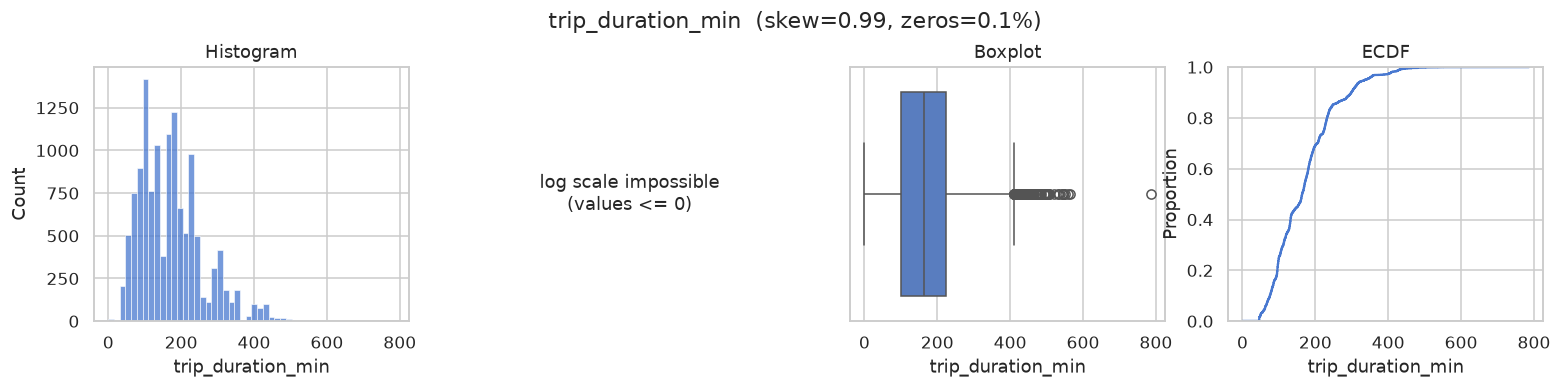

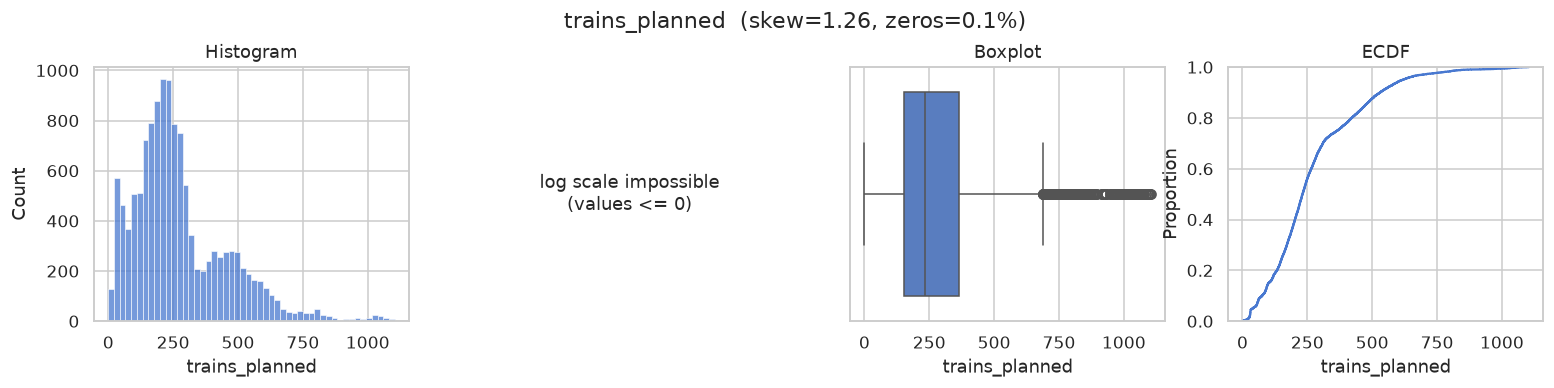

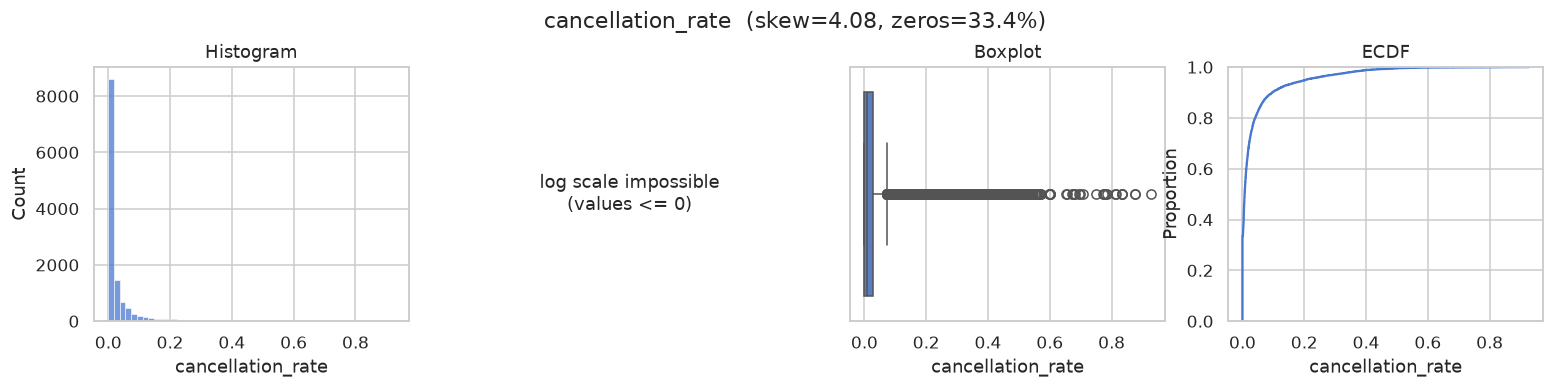

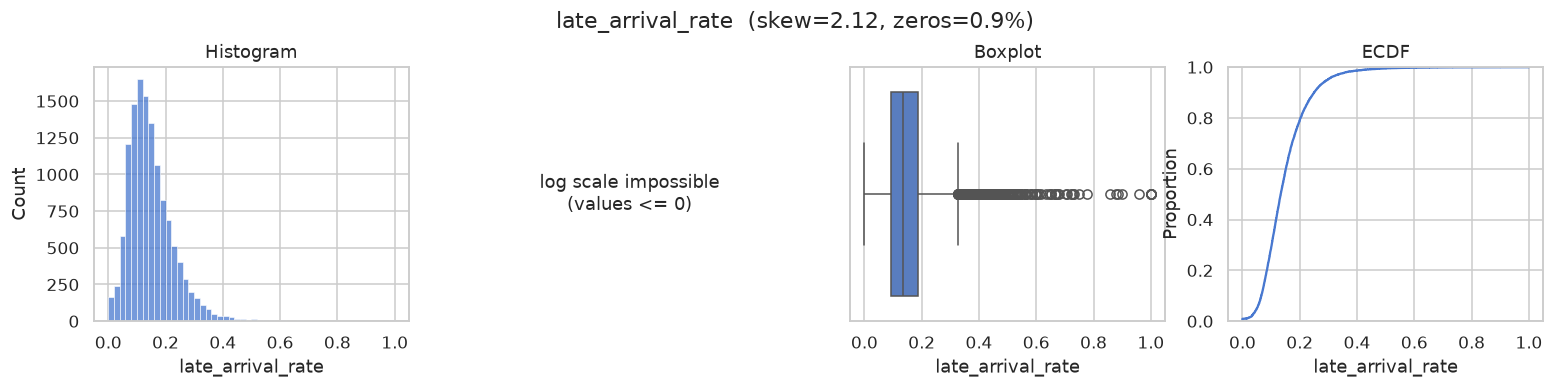

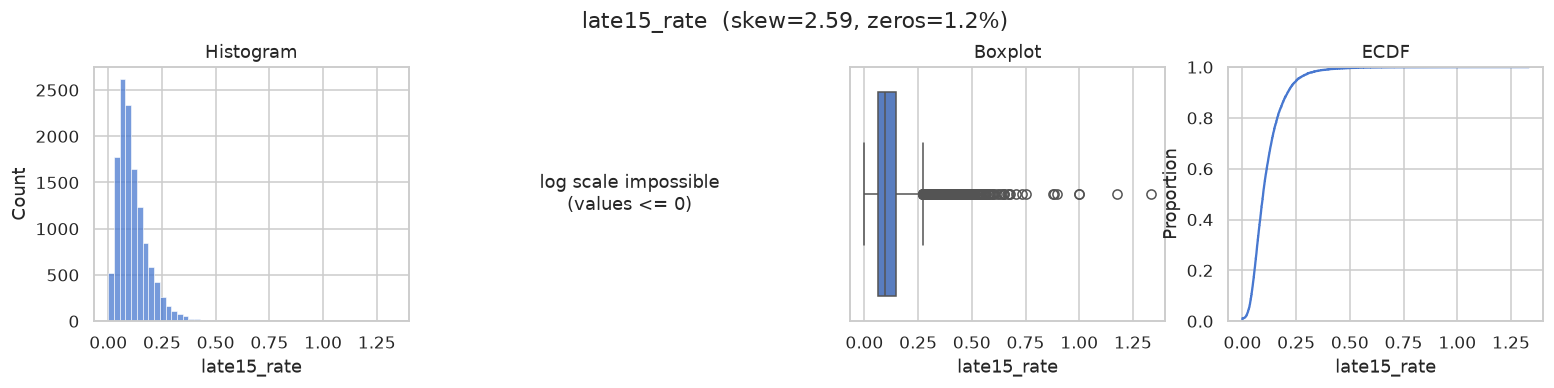

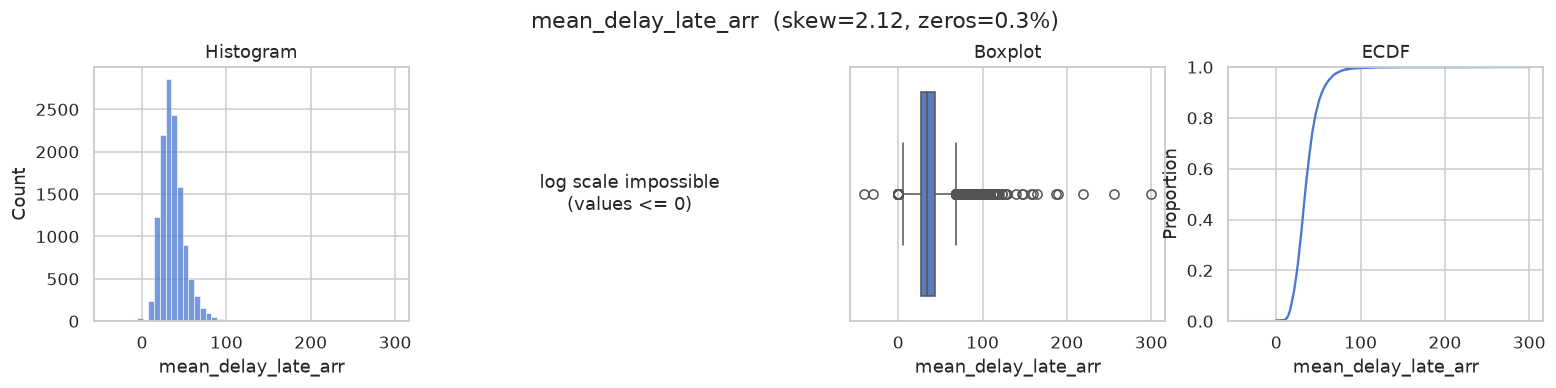

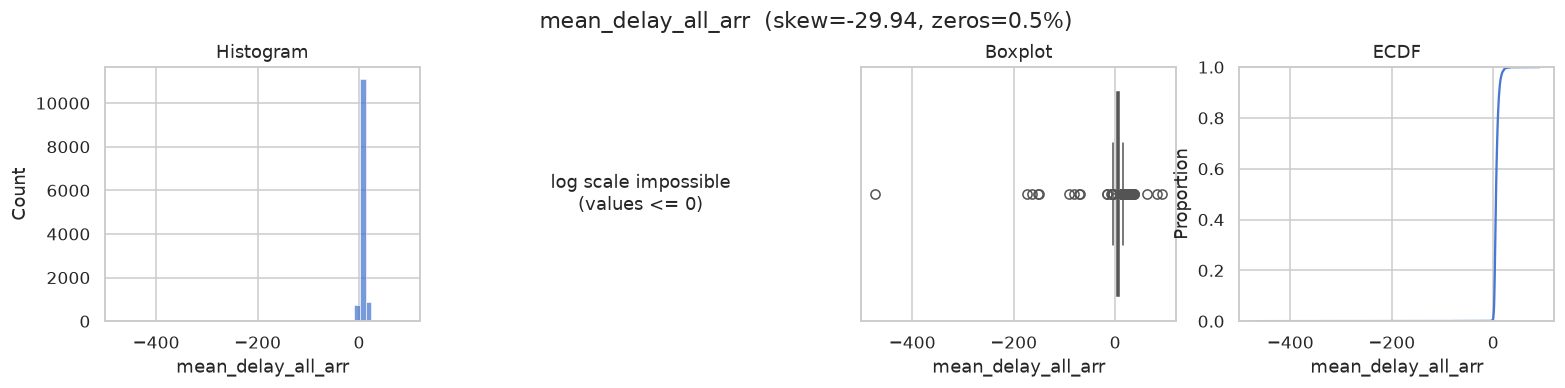

In [ ]:
def plot_distribution(data: pd.DataFrame, col: str) -> None:
    """Histogram (linear and log), boxplot and ECDF of one variable."""
    x = data[col].dropna()
    fig, axes = plt.subplots(1, 4, figsize=(17, 3))
    sns.histplot(x, bins=50, ax=axes[0])
    axes[0].set_title("Histogram")
    if (x > 0).all():
        sns.histplot(x, bins=50, log_scale=True, ax=axes[1])
        axes[1].set_title("Histogram (log x)")
    else:
        axes[1].text(0.5, 0.5, "log scale impossible\n(values <= 0)", ha="center", va="center")
        axes[1].set_axis_off()
    sns.boxplot(x=x, ax=axes[2])
    axes[2].set_title("Boxplot")
    sns.ecdfplot(x, ax=axes[3])
    axes[3].set_title("ECDF")
    fig.suptitle(f"{col}  (skew={x.skew():.2f}, zeros={(x == 0).mean():.1%})", y=1.05)
    plt.show()


for col in ["trip_duration_min", "trains_planned", "cancellation_rate", "late_arrival_rate",
            "late15_rate", "mean_delay_late_arr", "mean_delay_all_arr"]:
    plot_distribution(clean, col)

**Questions à se poser devant chaque graphique**
- *Forme* : une seule bosse ou plusieurs ? Plusieurs bosses (multimodalité) annoncent souvent
  des sous-populations (ex. liaisons courtes / longues) : c'est **précisément** ce qu'un
  clustering pourrait retrouver… ou ce qui pourrait le piéger.
- *Échelle* : si l'histogramme en log est plus lisible, la variable est multiplicative ; une
  transformation log (ou Yeo-Johnson) avant le clustering évitera que les extrêmes dominent.
- *ECDF* : lit directement « X % des mois-liaisons ont moins de Y % de trains en retard ».
- *Extrêmes* : sont-ils concentrés sur quelques mois ? (→ section 9, mois exceptionnels).

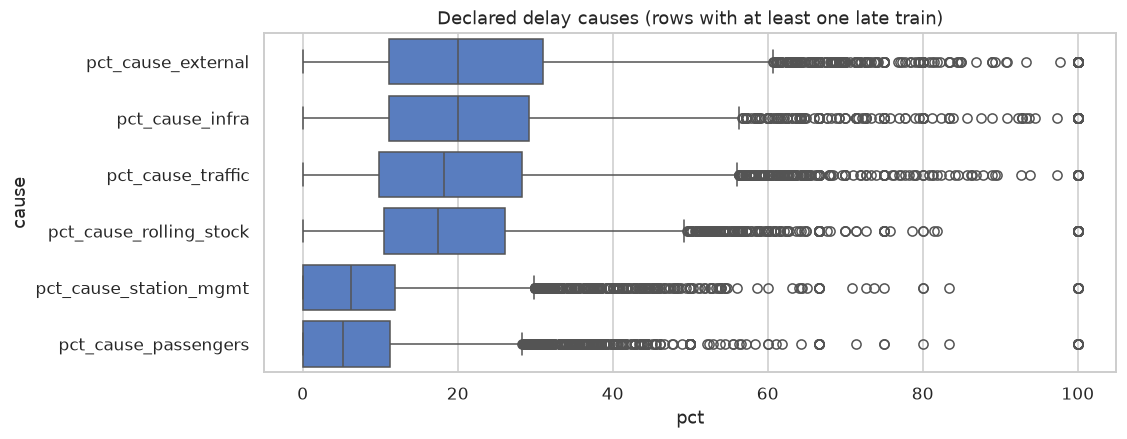

In [13]:
# Cause shares: compositional data (sum = 100) -> look at them together
fig, ax = plt.subplots(figsize=(10, 4))
clean[PCT_COLS].melt(var_name="cause", value_name="pct").pipe(
    lambda d: sns.boxplot(data=d, y="cause", x="pct", ax=ax))
ax.set_title("Declared delay causes (rows with at least one late train)")
plt.show()

## I.8 Univarié qualitatif

Pour une variable nominale : effectifs, modalités rares, **cohérence des libellés** (casse,
espaces, accents, abréviations). Deux libellés pour une même gare créent deux « liaisons »
distinctes et faussent tous les regroupements.

service
NATIONAL         11254
INTERNATIONAL     1547
Name: count, dtype: int64 



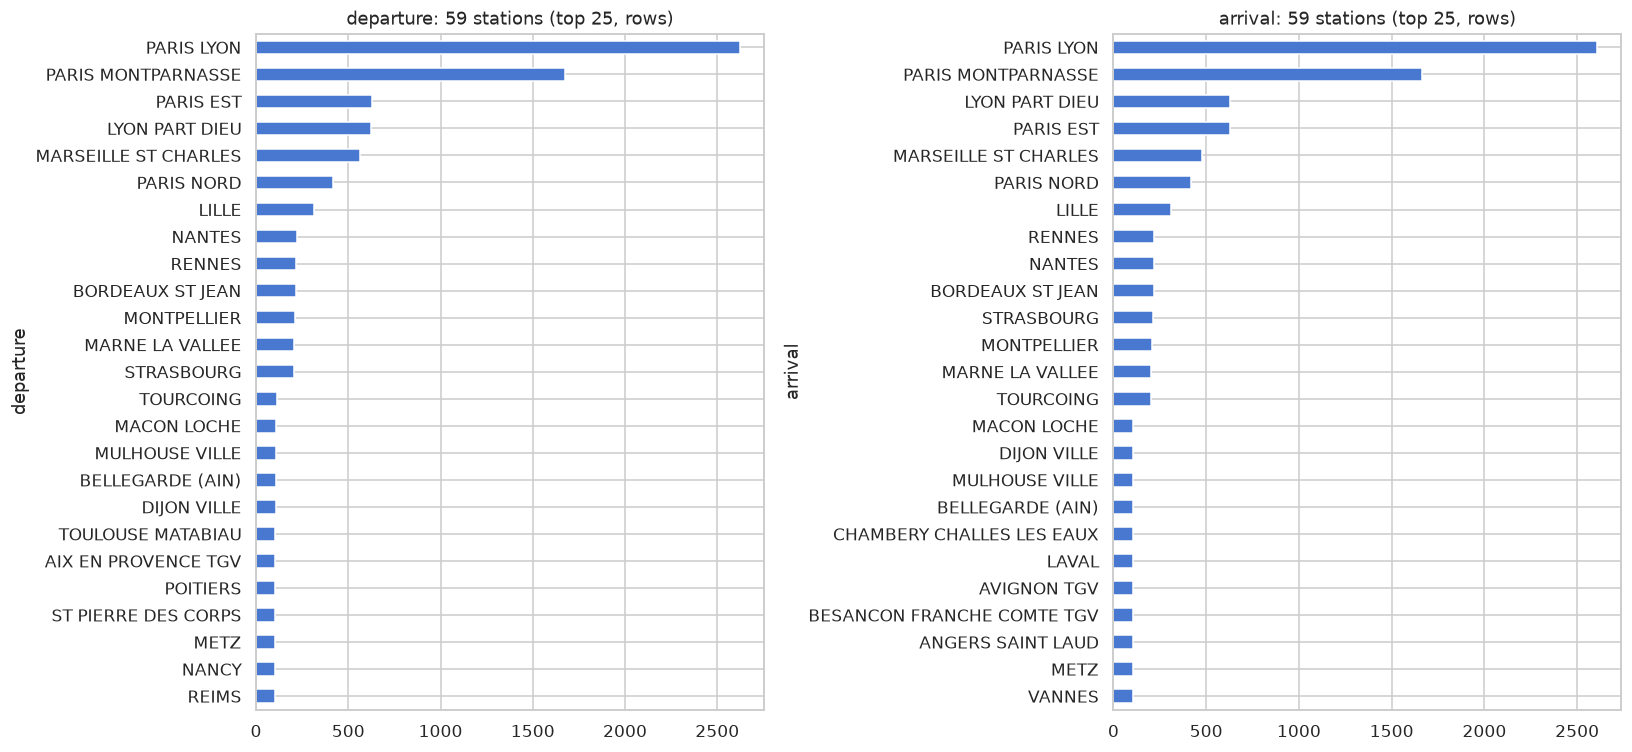

In [14]:
print(clean["service"].value_counts(), "\n")
fig, axes = plt.subplots(1, 2, figsize=(15, 7))
for ax, col in zip(axes, ["departure", "arrival"]):
    clean[col].value_counts().head(25).sort_values().plot.barh(ax=ax)
    ax.set_title(f"{col}: {clean[col].nunique()} stations (top 25, rows)")
plt.tight_layout(); plt.show()

In [15]:
# Near-duplicate station labels: same name once accents, punctuation and spaces are removed
import unicodedata


def normalise(label: str) -> str:
    """Upper-case ASCII key without punctuation or spaces."""
    ascii_label = unicodedata.normalize("NFKD", label).encode("ascii", "ignore").decode()
    return "".join(ch for ch in ascii_label.upper() if ch.isalnum())


stations = pd.Series(pd.unique(clean[["departure", "arrival"]].values.ravel()))
groups = stations.groupby(stations.map(normalise)).agg(list)
print("Labels that collapse to the same key:")
print(groups[groups.map(len) > 1])

Labels that collapse to the same key:
Series([], dtype: object)


In [16]:
# Routes: how many, observed in both directions?
pairs = set(zip(clean["departure"], clean["arrival"]))
both = sum((a, d) in pairs for d, a in pairs)
print(f"{len(pairs)} oriented routes; {both} have their reverse direction")
clean.groupby("route").size().describe()

130 oriented routes; 130 have their reverse direction


count   130.0000
mean     98.4692
std      22.1111
min      12.0000
25%     104.0000
50%     104.0000
75%     105.0000
max     108.0000
dtype: float64

## I.9 Univarié temporel

Trois questions :
1. **Panel équilibré ?** Toutes les liaisons sont-elles observées tous les mois ? Sinon, une
   « évolution » du réseau peut venir d'un changement de composition (Simpson, session 2).
2. **Mois exceptionnels ?** Détectés **à partir des données** (et non d'une liste écrite de
   mémoire), en comparant chaque mois au même mois calendaire des autres années, puis z-score
   robuste $> 3{,}5$.
3. **Saisonnalité** : heatmap année × mois du taux de retard réseau.

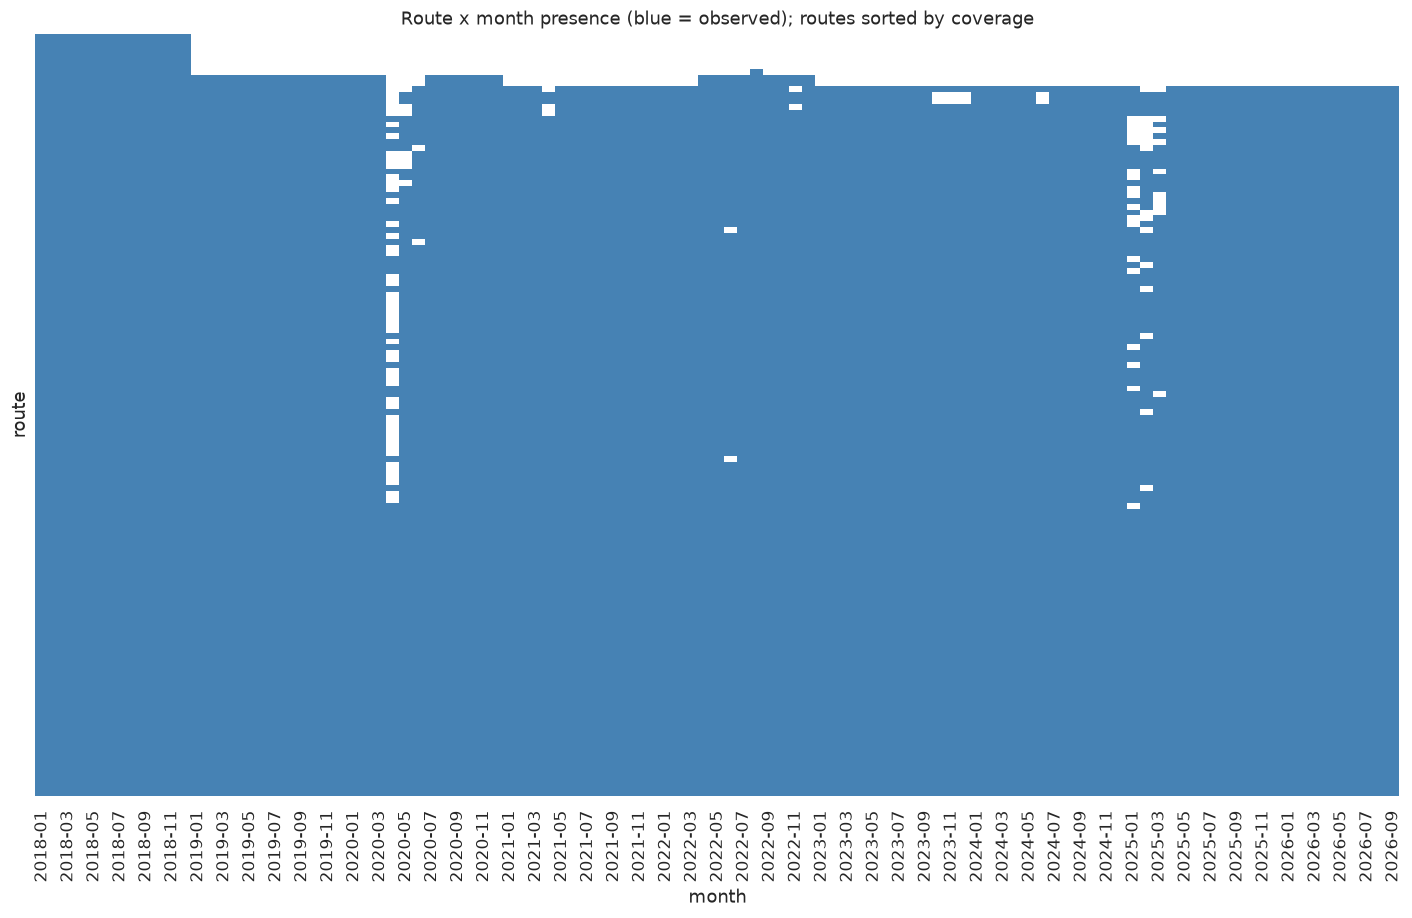

count   130.0000
mean     98.1462
std      22.0029
min      12.0000
25%     103.0000
50%     104.0000
75%     105.0000
max     105.0000
dtype: float64


In [17]:
presence = (clean.assign(month=clean["date"].astype(str))
            .pivot_table(index="route", columns="month", values="trains_planned", aggfunc="size")
            .notna())
fig, ax = plt.subplots(figsize=(16, 9))
sns.heatmap(presence.loc[presence.sum(axis=1).sort_values().index], cbar=False,
            cmap=["white", "steelblue"], ax=ax, yticklabels=False)
ax.set_title("Route x month presence (blue = observed); routes sorted by coverage")
plt.show()
print(presence.sum(axis=1).describe())

In [18]:
# ── Common block: data-driven exceptional months ───────────────────────────────
def robust_z(x: pd.Series) -> pd.Series:
    """Robust z-score: (x - median) / (1.4826 * MAD)."""
    mad = 1.4826 * (x - x.median()).abs().median()
    return (x - x.median()) / mad if mad > 0 else x * 0.0


def exceptional_months(data: pd.DataFrame, z_threshold: float = 3.5) -> list[str]:
    """Months where the whole network is abnormal, compared with the same calendar month."""
    net = data.groupby("date")[["trains_planned", "trains_cancelled", "late_15min", "trains_run"]].sum()
    rates = pd.DataFrame({
        "cancellation": net["trains_cancelled"] / net["trains_planned"],
        "late15": net["late_15min"] / net["trains_run"].clip(lower=1),
    })
    residual = rates - rates.groupby(rates.index.month).transform("median")
    flagged = (residual.apply(robust_z) > z_threshold).any(axis=1)
    return sorted(str(m) for m in rates.index[flagged])


EXCEPTIONAL_MONTHS = exceptional_months(clean)
print("Exceptional months (data-driven):", EXCEPTIONAL_MONTHS)

Exceptional months (data-driven): ['2018-02', '2018-04', '2018-05', '2018-06', '2018-07', '2019-06', '2019-07', '2019-12', '2020-01', '2020-03', '2020-04', '2020-05', '2020-06', '2020-11', '2020-12', '2021-04', '2021-05', '2022-12', '2023-01', '2023-02', '2023-03', '2024-02', '2026-01', '2026-06']


Detected but missing from the v1 manual list: ['2018-02', '2018-04', '2018-05', '2018-06', '2018-07', '2019-06', '2019-07', '2020-11', '2020-12', '2021-04', '2021-05', '2022-12', '2023-01', '2023-02', '2023-03', '2024-02', '2026-01', '2026-06']
In the v1 list but not detected: ['2020-02']


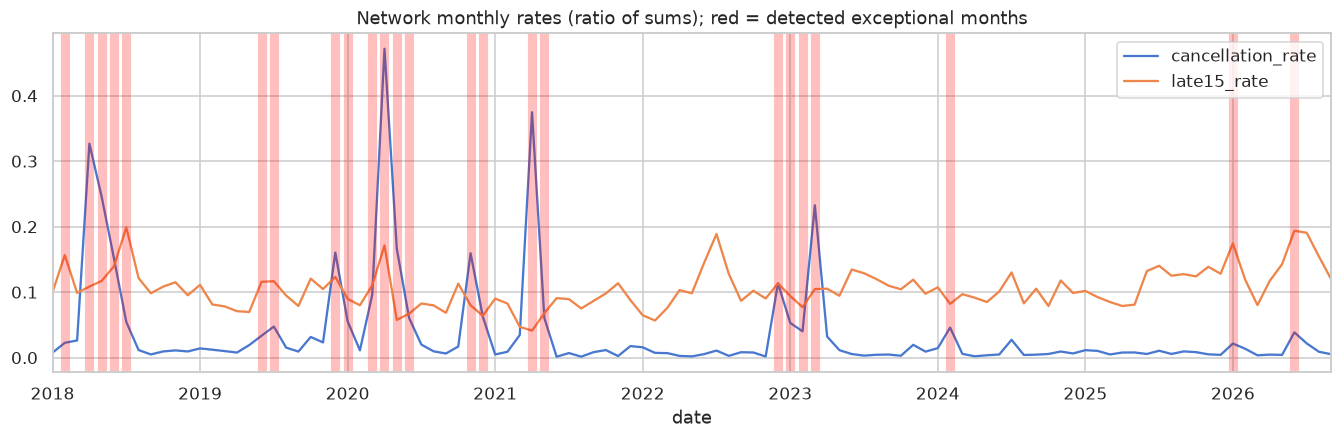

In [19]:
MANUAL_LIST_V1 = ["2019-12", "2020-01", "2020-02", "2020-03", "2020-04", "2020-05", "2020-06"]
print("Detected but missing from the v1 manual list:", sorted(set(EXCEPTIONAL_MONTHS) - set(MANUAL_LIST_V1)))
print("In the v1 list but not detected:", sorted(set(MANUAL_LIST_V1) - set(EXCEPTIONAL_MONTHS)))

net = clean.groupby("date")[["trains_planned", "trains_cancelled", "late_15min", "trains_run"]].sum()
net["cancellation_rate"] = net["trains_cancelled"] / net["trains_planned"]
net["late15_rate"] = net["late_15min"] / net["trains_run"]
ax = net[["cancellation_rate", "late15_rate"]].plot(figsize=(15, 4))
for m in EXCEPTIONAL_MONTHS:
    ax.axvline(pd.Period(m, "M"), color="red", alpha=0.25, linewidth=6)
ax.set_title("Network monthly rates (ratio of sums); red = detected exceptional months")
plt.show()

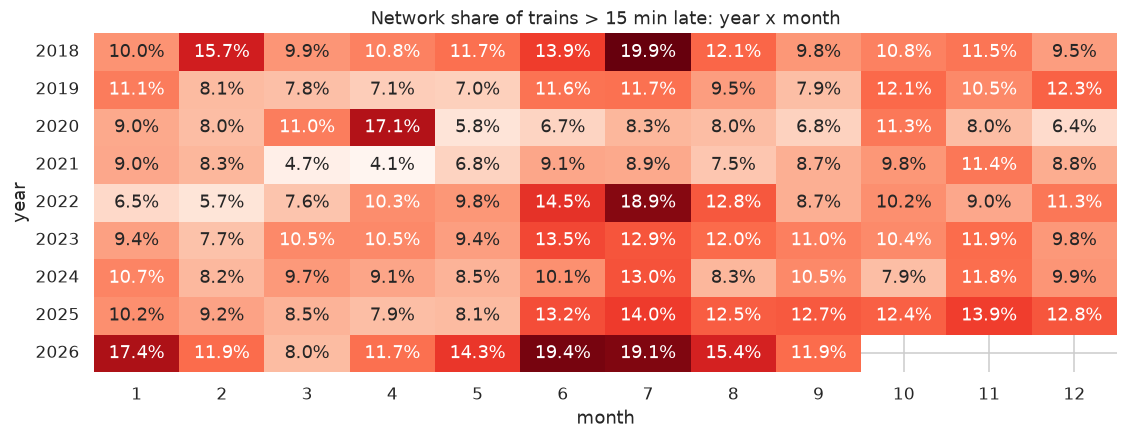

In [20]:
heat = net["late15_rate"].to_frame().assign(
    year=lambda d: d.index.year, month=lambda d: d.index.month
).pivot(index="year", columns="month", values="late15_rate")
plt.figure(figsize=(12, 4))
sns.heatmap(heat, annot=True, fmt=".1%", cmap="Reds", cbar=False)
plt.title("Network share of trains > 15 min late: year x month")
plt.show()

## 10. Synthèse pour le clustering (à compléter avec tes chiffres)

| Constat | Conséquence pour la Q3 |
|---|---|
| Comptages proportionnels à la taille de la liaison | Ne jamais clusteriser des comptages bruts : utiliser des **taux** |
| Seuil « en retard » composite (5/10/15 min selon la durée) | Les variables `late_arrival`, `mean_delay_late_arr` dépendent de la durée → préférer les seuils fixes 15/30 min (notebook 01) |
| Valeurs indéfinies codées 0 (D3) | Corrigées en `NaN` ; moyennes pondérées par le nombre de trains en retard |
| Variables asymétriques (skew > 1) | Transformation (log / Yeo-Johnson) ou scaler robuste avant K-means |
| Causes = composition (somme 100) | Ne pas les utiliser telles quelles comme variables de distance |
| Mois exceptionnels (liste détectée ci-dessus) | Exclus du calcul des profils, analyse de sensibilité avec |
| Liaisons à couverture partielle | Seuil d'éligibilité en nombre de mois |

# Partie II — Profils de ponctualité des liaisons (K-means)

**Question** : peut-on regrouper les liaisons par « profil de ponctualité » (bonne régularité,
retards chroniques mineurs, retards rares mais sévères…) à l'aide d'un clustering ?

**Type de question** : exploratoire. On peut conclure « les liaisons se répartissent en *k*
groupes de comportement distinct » **si** la structure résiste aux tests de la section 9 ;
on ne peut pas conclure *pourquoi* une liaison est dans un groupe.

### Paramètres (futurs widgets Streamlit)
Toute la suite dépend de ces 4 valeurs : ce sont exactement les contrôles à exposer dans l'app.

In [21]:
FEATURE_SET = "fixed"      # "fixed" (recommended) or "composite" (v1)  -> st.radio
SCALER = "power"           # "standard" or "power"                       -> st.selectbox
K = None                   # None = chosen by silhouette, or an int      -> st.select_slider
EXCLUDE_EXCEPTIONAL = True # sensitivity analysis                        -> st.toggle

In [22]:
COUNT_COLS = ["trains_planned", "trains_cancelled", "late_departure", "late_arrival",
              "late_15min", "late_30min", "late_60min"]
DELAY_COLS = ["mean_delay_late_dep", "mean_delay_all_dep",
              "mean_delay_late_arr", "mean_delay_all_arr"]
PCT_COLS = [c for c in COL_MAP.values() if c.startswith("pct_cause_")]
COMMENT_COLS = ["comment_cancellations", "comment_departure", "comment_arrival"]


def load_clean(path: Path) -> pd.DataFrame:
    """Load the raw export and apply the quality decisions of notebook 00."""
    df = pd.read_csv(path, sep=";", encoding="utf-8-sig").rename(columns=COL_MAP)
    # Types: month as a period, stations as clean upper-case strings, numbers as numbers
    df["date"] = pd.to_datetime(df["date"].astype(str)).dt.to_period("M")
    for col in ("service", "departure", "arrival"):
        df[col] = df[col].astype(str).str.strip().str.upper()
    num_cols = ["trip_duration_min", *COUNT_COLS, *DELAY_COLS, *PCT_COLS]
    df[num_cols] = df[num_cols].apply(pd.to_numeric, errors="coerce")
    # D1: impossible negative counts -> missing
    df[COUNT_COLS] = df[COUNT_COLS].mask(df[COUNT_COLS] < 0)
    # D2: more cancelled than planned is impossible -> row flagged and excluded
    df["is_invalid"] = (df["trains_cancelled"] > df["trains_planned"]) | df[COUNT_COLS].isna().any(axis=1)
    # D3: "mean delay of late trains" and cause shares do not exist without late
    #     trains: the 0 written by SNCF is a disguised missing value -> NaN
    df.loc[df["late_arrival"] == 0, ["mean_delay_late_arr", *PCT_COLS]] = np.nan
    df.loc[df["late_departure"] == 0, "mean_delay_late_dep"] = np.nan
    # D4: empty comments and an undocumented column are dropped
    df = df.drop(columns=[*COMMENT_COLS, "delay_15_flight_unclear"])
    # D5: negative "mean delay of ALL trains" = early trains on average -> kept
    df["route"] = df["departure"] + " → " + df["arrival"]
    df["trains_run"] = df["trains_planned"] - df["trains_cancelled"]
    return df


df_all = load_clean(RAW_PATH)
df = df_all[~df_all["is_invalid"]].copy()
print(f"{len(df_all)} rows, {df_all['is_invalid'].sum()} invalid rows excluded -> {len(df)} rows")
print(f"{df['route'].nunique()} routes, {df['date'].nunique()} months "
      f"({df['date'].min()} -> {df['date'].max()})")

12907 rows, 106 invalid rows excluded -> 12801 rows
130 routes, 105 months (2018-01 -> 2026-09)


In [23]:
# data-driven exceptional months

def robust_z(x: pd.Series) -> pd.Series:
    """Robust z-score: (x - median) / (1.4826 * MAD)."""
    mad = 1.4826 * (x - x.median()).abs().median()
    return (x - x.median()) / mad if mad > 0 else x * 0.0


def exceptional_months(data: pd.DataFrame, z_threshold: float = 3.5) -> list[str]:
    """Months where the whole network is abnormal, compared with the same calendar month."""
    net = data.groupby("date")[["trains_planned", "trains_cancelled", "late_15min", "trains_run"]].sum()
    rates = pd.DataFrame({
        "cancellation": net["trains_cancelled"] / net["trains_planned"],
        "late15": net["late_15min"] / net["trains_run"].clip(lower=1),
    })
    residual = rates - rates.groupby(rates.index.month).transform("median")
    flagged = (residual.apply(robust_z) > z_threshold).any(axis=1)
    return sorted(str(m) for m in rates.index[flagged])


EXCEPTIONAL_MONTHS = exceptional_months(df)
print("Exceptional months (data-driven):", EXCEPTIONAL_MONTHS)
df_normal = df[~df["date"].astype(str).isin(EXCEPTIONAL_MONTHS)].copy()

if not EXCLUDE_EXCEPTIONAL:
    df_normal = df.copy()

Exceptional months (data-driven): ['2018-02', '2018-04', '2018-05', '2018-06', '2018-07', '2019-06', '2019-07', '2019-12', '2020-01', '2020-03', '2020-04', '2020-05', '2020-06', '2020-11', '2020-12', '2021-04', '2021-05', '2022-12', '2023-01', '2023-02', '2023-03', '2024-02', '2026-01', '2026-06']


In [ ]:
# route-level features 

def build_route_features(data: pd.DataFrame) -> pd.DataFrame:
    """One row per route: fixed-threshold AND composite-threshold features."""
    g = data.groupby("route")
    s = g[["trains_planned", "trains_cancelled", "trains_run", "late_arrival",
           "late_15min", "late_30min", "late_60min"]].sum()
    out = pd.DataFrame(index=s.index)
    out["n_months"] = g["date"].nunique()
    out["trains_run_total"] = s["trains_run"]
    out["trip_duration_min"] = g["trip_duration_min"].median()
    # Fixed thresholds (recommended): comparable across trip durations
    out["cancellation_rate"] = s["trains_cancelled"] / s["trains_planned"]
    out["late15_rate"] = s["late_15min"] / s["trains_run"]
    out["severe_share"] = (s["late_30min"] / s["late_15min"]).fillna(0)
    run = data[data["trains_run"] > 0].assign(
        r15=lambda d: d["late_15min"] / d["trains_run"])
    net = run.groupby("date")[["late_15min", "trains_run"]].sum()
    run = run.join((net["late_15min"] / net["trains_run"]).rename("net_r15"), on="date")
    out["volatility"] = run.groupby("route")["r15"].std().fillna(0)
    out["chronicity"] = (run["r15"] > run["net_r15"]).groupby(run["route"]).mean()
    # Composite threshold (original notebook): threshold depends on trip duration
    out["late_arrival_rate"] = s["late_arrival"] / s["trains_run"]
    w = data["mean_delay_late_arr"] * data["late_arrival"]
    out["mean_delay_when_late"] = w.groupby(data["route"]).sum() / s["late_arrival"]
    out["severe_ratio"] = s["late_30min"] / s["late_arrival"]
    out["irregularity"] = run.assign(
        rc=lambda d: d["late_arrival"] / d["trains_run"]).groupby("route")["rc"].std().fillna(0)
    return out


FIXED_FEATURES = ["cancellation_rate", "late15_rate", "severe_share", "volatility", "chronicity"]
COMPOSITE_FEATURES = ["cancellation_rate", "late_arrival_rate", "mean_delay_when_late",
                      "severe_ratio", "irregularity"]

MIN_MONTHS = 24  # a threshold that can also appear as a parameter in Streamlit

routes = build_route_features(df_normal)
eligible = routes[routes["n_months"] >= MIN_MONTHS].copy()
print(f"{len(eligible)} eligible routes / {len(routes)} (>= {MIN_MONTHS} months)")

123 eligible routes / 130 (>= 24 months)


## II.2 Les indicateurs, en formules

**Notations.** Pour une liaison $r$ et un mois $m \in \mathcal{M}_r$ (mois observés, hors mois
exceptionnels) :

| Symbole | Signification | Colonne |
|---|---|---|
| $P_{r,m}$ | trains prévus | `trains_planned` |
| $A_{r,m}$ | trains annulés | `trains_cancelled` |
| $C_{r,m} = P_{r,m} - A_{r,m}$ | trains circulés | `trains_run` |
| $L^{15}_{r,m},\ L^{30}_{r,m},\ L^{60}_{r,m}$ | trains arrivés avec plus de 15, 30, 60 min de retard | `late_15min`… |
| $L^{\theta}_{r,m}$ | trains « en retard » au seuil composite $\theta(D_r)$ | `late_arrival` |
| $\bar{d}_{r,m}$ | retard moyen des trains en retard (seuil composite) | `mean_delay_late_arr` |

avec le seuil composite $\theta(D) = 5$ min si $D < 90$, $10$ min si $90 \le D \le 180$,
$15$ min sinon ($D$ = durée du trajet).

### Jeu « seuils fixes » (recommandé)

**1. Taux d'annulation** — les trains circulent-ils ?
$$\tau^{\text{ann}}_r = \frac{\sum_{m \in \mathcal{M}_r} A_{r,m}}{\sum_{m \in \mathcal{M}_r} P_{r,m}}$$

**2. Fréquence des retards > 15 min** — à quelle fréquence est-on nettement en retard ?
$$\tau^{15}_r = \frac{\sum_{m} L^{15}_{r,m}}{\sum_{m} C_{r,m}}$$

C'est un **ratio de sommes**. Il équivaut à une moyenne des taux mensuels pondérée par le
trafic, ce qui évite qu'un mois à 20 trains pèse autant qu'un mois à 900 :
$$\tau^{15}_r = \sum_{m} w_{r,m}\,\frac{L^{15}_{r,m}}{C_{r,m}}, \qquad w_{r,m} = \frac{C_{r,m}}{\sum_{m'} C_{r,m'}}$$

**3. Sévérité conditionnelle** — quand on est en retard de plus de 15 min, est-ce grave ?
$$s_r = \frac{\sum_{m} L^{30}_{r,m}}{\sum_{m} L^{15}_{r,m}} \;\approx\; \Pr(\text{retard} > 30 \mid \text{retard} > 15)$$

C'est l'axe qui sépare « retards fréquents mais courts » de « retards rares mais sévères ».

**4. Volatilité** — le comportement change-t-il d'un mois à l'autre ?
$$\sigma_r = \sqrt{\frac{1}{|\mathcal{M}^{+}_r| - 1}\sum_{m \in \mathcal{M}^{+}_r}\left(\tau^{15}_{r,m} - \overline{\tau^{15}_{r}}\right)^2},\qquad \tau^{15}_{r,m} = \frac{L^{15}_{r,m}}{C_{r,m}}$$
où $\mathcal{M}^{+}_r$ = mois avec au moins un train circulé. ⚠️ Pour une proportion, la variance
binomiale $p(1-p)/C$ augmente avec $p$ quand $p < 0{,}5$ : $\sigma_r$ est mécaniquement liée à
$\tau^{15}_r$ (à vérifier dans la matrice de corrélation).

**5. Chronicité** — la liaison fait-elle pire que le réseau *le même mois* ?
$$\chi_r = \frac{1}{|\mathcal{M}^{+}_r|}\sum_{m \in \mathcal{M}^{+}_r}\mathbb{1}\!\left[\tau^{15}_{r,m} > \tau^{15,\text{réseau}}_{m}\right],\qquad \tau^{15,\text{réseau}}_{m} = \frac{\sum_{r'} L^{15}_{r',m}}{\sum_{r'} C_{r',m}}$$
Comparer au réseau du même mois neutralise saisonnalité et chocs nationaux.

### Jeu « composite » (v1, conservé pour comparaison)
$$\tau^{\theta}_r = \frac{\sum_m L^{\theta}_{r,m}}{\sum_m C_{r,m}},\qquad
\bar{d}_r = \frac{\sum_m \bar{d}_{r,m}\,L^{\theta}_{r,m}}{\sum_m L^{\theta}_{r,m}},\qquad
\rho_r = \frac{\sum_m L^{30}_{r,m}}{\sum_m L^{\theta}_{r,m}}$$

**Le problème** : $\theta$ dépend de la durée. Une liaison courte ($\theta = 5$ min) compte
beaucoup de « petits » retards dans $L^{\theta}$, donc un $\rho_r$ faible et un $\bar{d}_r$
faible ; une liaison longue ($\theta = 15$ min) ne compte que les gros retards, donc $\rho_r$
et $\bar{d}_r$ élevés. **La durée fabrique une partie de la « sévérité »**. La section 3 le teste.

## II.3 Diagnostic : les indicateurs dépendent-ils de la durée du trajet ?

Si un indicateur est fortement corrélé à la durée, les clusters risquent de **redécouvrir la
durée ( c'est à dire redécouvrir qu'il y'a des liaisons de durée différentes et formé des groupes par rapport à ça)** plutôt qu'un comportement de ponctualité. On utilise Spearman (relation monotone,
robuste aux extrêmes).

In [ ]:
corr_duration = pd.DataFrame({
    "spearman_with_duration": eligible[FIXED_FEATURES + COMPOSITE_FEATURES]
    .corrwith(eligible["trip_duration_min"], method="spearman")
}).drop_duplicates()
corr_duration.style.format("{:.2f}").background_gradient(cmap="RdBu_r", vmin=-1, vmax=1)

,spearman_with_duration
cancellation_rate,0.19
late15_rate,0.72
severe_share,0.40
volatility,0.79
chronicity,0.69
late_arrival_rate,0.11
mean_delay_when_late,0.85
severe_ratio,0.90
irregularity,0.41


**Lecture** : |ρ| > 0,5 sur `mean_delay_when_late` ou `severe_ratio` mais pas sur
`severe_share` confirmerait que le jeu composite mesure en partie la durée. Ce n'est pas
interdit d'avoir des profils liés à la durée, mais ils doivent venir du **comportement**, pas
de la **définition** de la variable.

## II.4 Distributions et redondance

Deux variables corrélées à |ρ| > 0,8 mesurent presque la même chose : les garder toutes les
deux revient à **doubler le poids** de cette dimension dans la distance euclidienne.
On compare Pearson (linéaire) et Spearman (rangs) : un écart signale non-linéarité ou extrêmes.

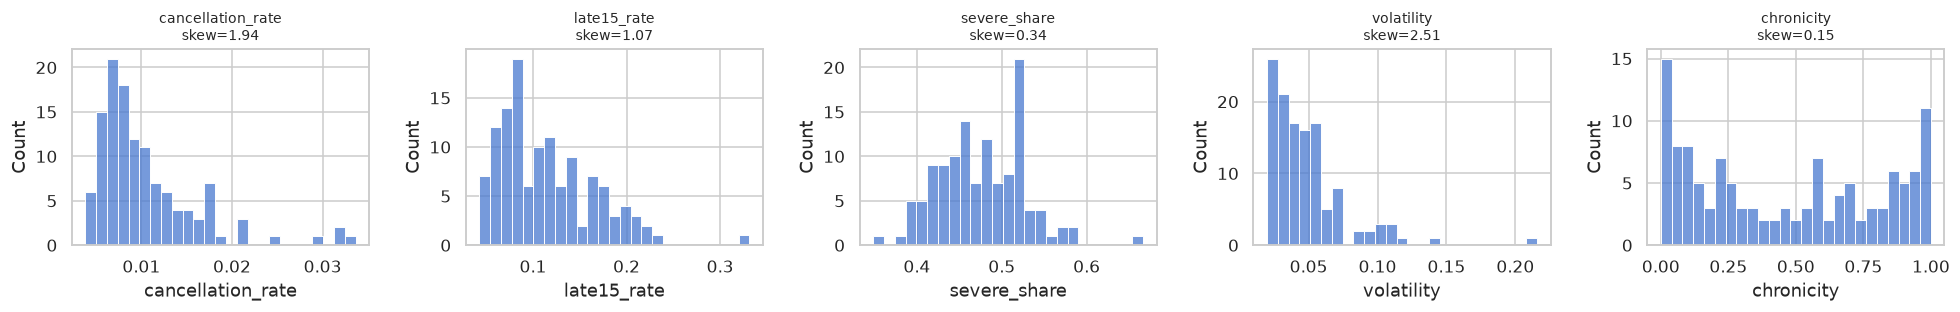

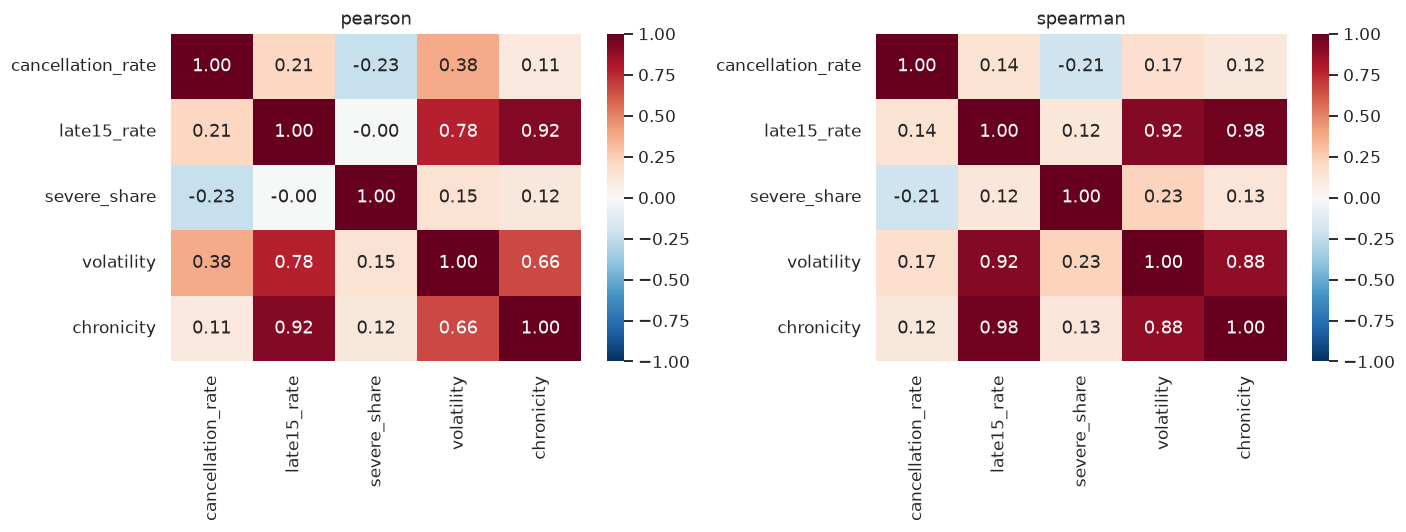

In [26]:
FEATURES = FIXED_FEATURES if FEATURE_SET == "fixed" else COMPOSITE_FEATURES
Xdf = eligible[FEATURES]

fig, axes = plt.subplots(1, len(FEATURES), figsize=(18, 3))
for ax, col in zip(axes, FEATURES):
    sns.histplot(Xdf[col], bins=25, ax=ax)
    ax.set_title(f"{col}\nskew={Xdf[col].skew():.2f}", fontsize=9)
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, method in zip(axes, ["pearson", "spearman"]):
    sns.heatmap(Xdf.corr(method=method), annot=True, fmt=".2f", cmap="RdBu_r",
                vmin=-1, vmax=1, ax=ax)
    ax.set_title(method)
plt.tight_layout(); plt.show()

## II.5 Mise à l'échelle

K-means minimise une distance euclidienne : sans mise à l'échelle, la variable de plus grande
variance numérique décide seule des groupes.

- **Standardisation** : $z_{ij} = \dfrac{x_{ij} - \mu_j}{\sigma_j}$ — sensible aux extrêmes et
  ne corrige pas l'asymétrie.
- **Yeo-Johnson** (`PowerTransformer`) : transformation $\psi_\lambda(x)$ choisie par maximum de
  vraisemblance pour rendre chaque variable aussi gaussienne que possible, **puis**
  standardisation. Pour $x \ge 0$ :
$$\psi_\lambda(x) = \begin{cases}\dfrac{(x+1)^\lambda - 1}{\lambda} & \lambda \ne 0\\[4pt] \ln(x+1) & \lambda = 0\end{cases}$$
  Utile ici car les taux sont asymétriques (quelques liaisons très dégradées).

In [27]:
from sklearn.preprocessing import PowerTransformer, StandardScaler

scaler = PowerTransformer(method="yeo-johnson") if SCALER == "power" else StandardScaler()
X = scaler.fit_transform(Xdf)
pd.DataFrame({"skew_before": Xdf.skew(), "skew_after": pd.DataFrame(X, columns=FEATURES).skew().values})

,skew_before,skew_after
cancellation_rate,1.9407,0.2582
late15_rate,1.0704,0.1324
severe_share,0.3360,-0.0015
volatility,2.5062,0.2322
chronicity,0.1535,-0.0118


## II.6 Choix du nombre de profils $k$

**K-means** cherche $k$ centres $\mu_1, \dots, \mu_k$ minimisant l'**inertie** intra-classe :
$$\min_{C_1,\dots,C_k}\; \sum_{j=1}^{k}\sum_{i \in C_j}\lVert x_i - \mu_j\rVert^2$$
L'inertie diminue toujours quand $k$ augmente : on cherche le « coude ».

**Silhouette** d'une liaison $i$, avec $a(i)$ = distance moyenne aux membres de son cluster et
$b(i)$ = distance moyenne au cluster voisin le plus proche :
$$s(i) = \frac{b(i) - a(i)}{\max\{a(i),\, b(i)\}} \in [-1, 1]$$
Repères usuels de la moyenne : $> 0{,}5$ structure nette ; $0{,}25$–$0{,}5$ structure moyenne
(groupes qui se chevauchent) ; $< 0{,}25$ structure faible.

Critère supplémentaire : la **taille du plus petit groupe** (un « profil » de 2 liaisons est un
outlier, pas un profil).

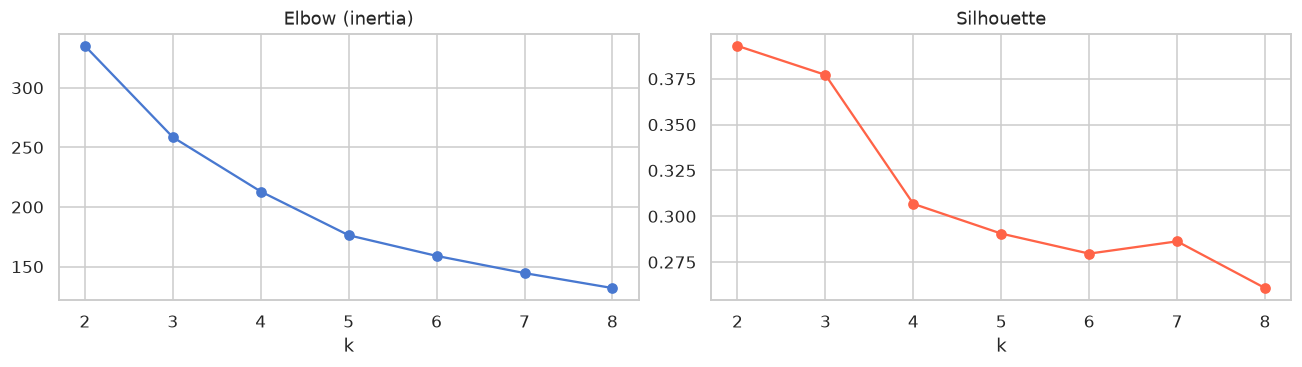

k = 2


,inertia,silhouette,smallest_cluster
k,,,
2,335.0484,0.3929,59
3,258.4854,0.3771,17
4,212.9475,0.3068,17
5,176.2684,0.2905,15
6,158.9580,0.2796,14
7,144.5450,0.2863,3
8,131.9954,0.2608,9


In [28]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

rows = []
for k in range(2, 9):
    km = KMeans(n_clusters=k, n_init=20, random_state=SEED).fit(X)
    rows.append({"k": k, "inertia": km.inertia_, "silhouette": silhouette_score(X, km.labels_),
                 "smallest_cluster": np.bincount(km.labels_).min()})
k_table = pd.DataFrame(rows).set_index("k")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 3.5))
k_table["inertia"].plot(marker="o", ax=ax1, title="Elbow (inertia)")
k_table["silhouette"].plot(marker="o", ax=ax2, color="tomato", title="Silhouette")
plt.tight_layout(); plt.show()

valid = k_table[k_table["smallest_cluster"] >= 3]
K_FINAL = K or int(valid["silhouette"].idxmax())
print(f"k = {K_FINAL}")
k_table

## II.7 Ajustement, réordonnancement et nommage **à partir des données**

Deux corrections :
1. on **réordonne** les clusters par fréquence de retard croissante (0 = le plus ponctuel) ;
2. on **nomme** chaque cluster par une règle explicite comparant son centroïde à la liaison
   médiane, sur deux axes : fréquence et sévérité. Les noms restent à valider à la lecture.

In [29]:
km = KMeans(n_clusters=K_FINAL, n_init=50, random_state=SEED).fit(X)
freq_col = "late15_rate" if FEATURE_SET == "fixed" else "late_arrival_rate"
sev_col = "severe_share" if FEATURE_SET == "fixed" else "severe_ratio"

# 1. Reorder labels by increasing delay frequency
order = Xdf.groupby(km.labels_)[freq_col].mean().sort_values().index
relabel = {old: new for new, old in enumerate(order)}
eligible["cluster"] = [relabel[label] for label in km.labels_]

# 2. Name clusters from their centroid vs the median route
centroids = eligible.groupby("cluster")[FEATURES].mean()
median = Xdf.median()
TOL = 0.15


def level(value: float, ref: float) -> str:
    """'high', 'low' or 'mid' relative to a reference, with a tolerance band."""
    return "high" if value > ref * (1 + TOL) else "low" if value < ref * (1 - TOL) else "mid"


def name_profile(c: pd.Series) -> str:
    """Rule-based archetype name for one centroid."""
    f, s = level(c[freq_col], median[freq_col]), level(c[sev_col], median[sev_col])
    name = ("Retards chroniques" if f == "high" and s == "high" else
            "Retards fréquents mais courts" if f == "high" else
            "Retards rares mais sévères" if s == "high" else
            "Fiables" if f == "low" else "Dans la moyenne")
    if c["cancellation_rate"] > 1.5 * median["cancellation_rate"]:
        name += " (+ annulations)"
    return name


names = {k: f"{k} · {name_profile(c)}" for k, c in centroids.iterrows()}
eligible["profile"] = eligible["cluster"].map(names)
centroids.index = centroids.index.map(names)
display(centroids.assign(n_routes=eligible["profile"].value_counts()))

,cancellation_rate,late15_rate,severe_share,volatility,chronicity,n_routes
cluster,,,,,,
0 · Fiables,0.0100,0.0732,0.4647,0.0297,0.1420,59
1 · Retards fréquents mais courts,0.0112,0.1528,0.4877,0.0662,0.7584,64


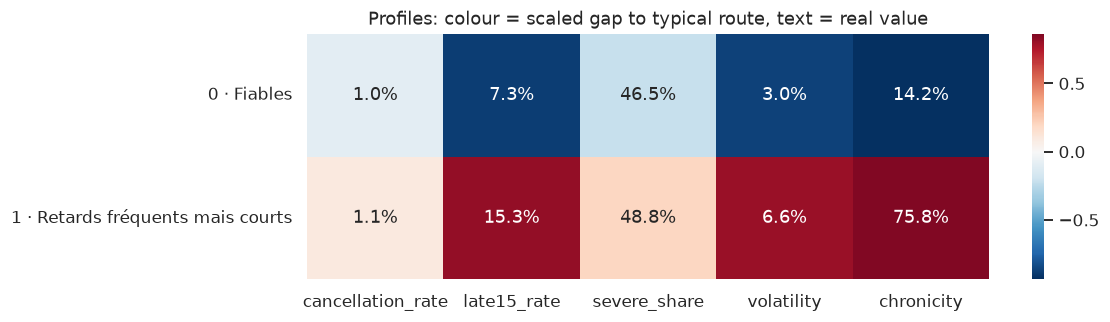

In [30]:
# Standardised centroids: what distinguishes each profile (0 = typical route)
z_centroids = pd.DataFrame(X, columns=FEATURES).groupby(eligible["cluster"].values).mean()
z_centroids.index = z_centroids.index.map(names)
plt.figure(figsize=(10, 0.7 * K_FINAL + 1.5))
sns.heatmap(z_centroids, annot=centroids.map(lambda v: f"{v:.1%}"), fmt="",
            cmap="RdBu_r", center=0)
plt.title("Profiles: colour = scaled gap to typical route, text = real value")
plt.show()

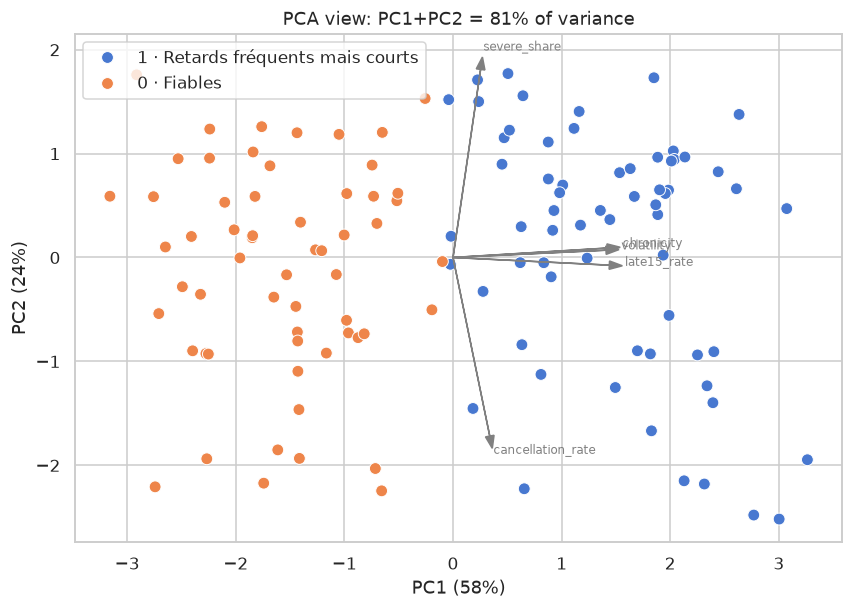

In [31]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2, random_state=SEED).fit(X)
coords = pca.transform(X)
ev = pca.explained_variance_ratio_
fig, ax = plt.subplots(figsize=(9, 6))
sns.scatterplot(x=coords[:, 0], y=coords[:, 1], hue=eligible["profile"].values, s=60, ax=ax)
for feat, (x1, y1) in zip(FEATURES, pca.components_.T * 2.5):
    ax.arrow(0, 0, x1, y1, color="grey", head_width=0.08)
    ax.text(x1 * 1.1, y1 * 1.1, feat, color="grey", fontsize=8)
ax.set_xlabel(f"PC1 ({ev[0]:.0%})"); ax.set_ylabel(f"PC2 ({ev[1]:.0%})")
ax.set_title(f"PCA view: PC1+PC2 = {ev.sum():.0%} of variance")
plt.show()

In [32]:
for profile, group in eligible.sort_values("trains_run_total", ascending=False).groupby("profile"):
    print(f"\n{profile} ({len(group)} routes)")
    print("   " + "\n   ".join(group.index[:6]))


0 · Fiables (59 routes)
   PARIS MONTPARNASSE → BORDEAUX ST JEAN
   PARIS MONTPARNASSE → RENNES
   RENNES → PARIS MONTPARNASSE
   PARIS LYON → LYON PART DIEU
   LYON PART DIEU → PARIS LYON
   PARIS NORD → LILLE

1 · Retards fréquents mais courts (64 routes)
   BORDEAUX ST JEAN → PARIS MONTPARNASSE
   PARIS LYON → MARSEILLE ST CHARLES
   STRASBOURG → PARIS EST
   MARSEILLE ST CHARLES → PARIS LYON
   MARSEILLE ST CHARLES → LYON PART DIEU
   LYON PART DIEU → MARSEILLE ST CHARLES


## II.8 Le profil reflète-t-il un comportement ou la durée du trajet ?

On refait le clustering avec **l'autre** jeu d'indicateurs et on compare :
- la **durée des trajets** par profil dans chaque version ;
- l'**accord** entre les deux partitions (ARI).

ARI fixed vs composite = 0.87


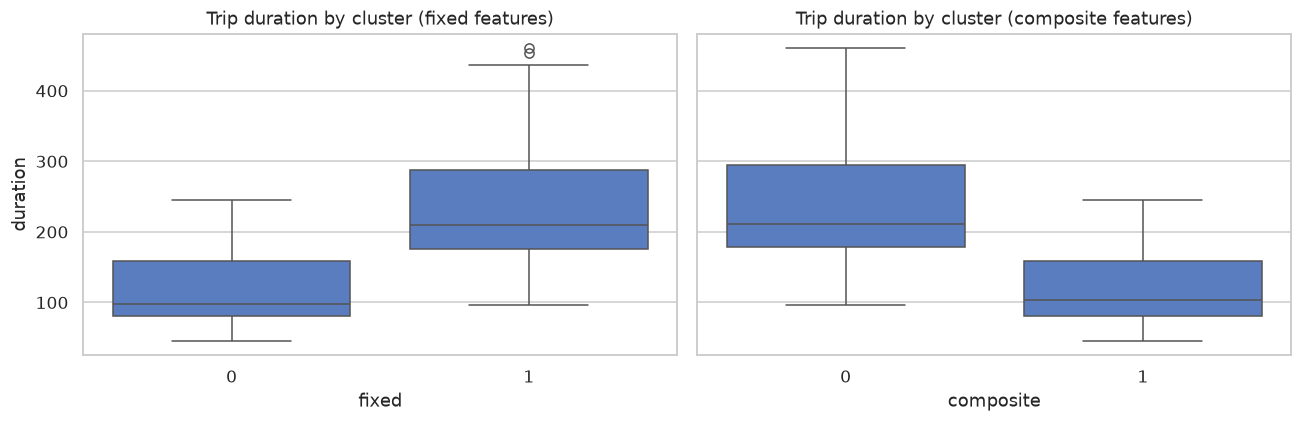

In [33]:
from sklearn.metrics import adjusted_rand_score


def kmeans_labels(features: list[str], k: int) -> np.ndarray:
    """Scale with the same scaler type and run K-means."""
    sc = PowerTransformer() if SCALER == "power" else StandardScaler()
    return KMeans(n_clusters=k, n_init=20, random_state=SEED).fit_predict(
        sc.fit_transform(eligible[features]))


comparison = pd.DataFrame({
    "fixed": kmeans_labels(FIXED_FEATURES, K_FINAL),
    "composite": kmeans_labels(COMPOSITE_FEATURES, K_FINAL),
    "duration": eligible["trip_duration_min"].values,
})
print(f"ARI fixed vs composite = {adjusted_rand_score(comparison['fixed'], comparison['composite']):.2f}")
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, col in zip(axes, ["fixed", "composite"]):
    sns.boxplot(data=comparison, x=col, y="duration", ax=ax)
    ax.set_title(f"Trip duration by cluster ({col} features)")
plt.tight_layout(); plt.show()

## II.9 Robustesse : trois tests qui ne mesurent pas la même chose

| Test | Ce qu'on fait varier | Question posée |
|---|---|---|
| Graines | l'initialisation de K-means | l'algorithme converge-t-il toujours vers la même solution ? |
| Rééchantillonnage | les **liaisons** (80 % tirées au hasard, 30 fois) | les groupes tiennent-ils si les données changent un peu ? |
| Permutation | on **mélange** chaque colonne indépendamment | la structure est-elle meilleure que sur des données sans structure ? |

La v1 ne faisait que le premier, qui est le plus faible : un ARI de 1 entre graines prouve
seulement que l'optimisation est stable, pas que les profils existent.

L'**indice de Rand ajusté** (ARI) compare deux partitions : 1 = identiques, ≈ 0 = accord pas
meilleur que le hasard.

Seeds         : mean ARI = 0.95
Resampling    : median ARI = 0.92 (min 0.84)
Permutation   : real silhouette 0.393 vs shuffled max 0.186


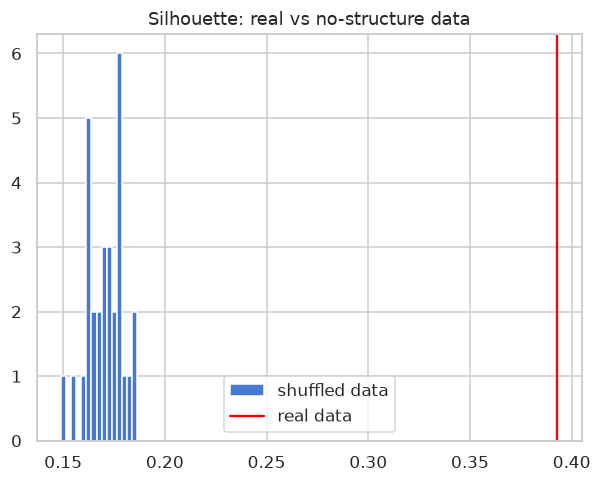

In [34]:
rng = np.random.default_rng(SEED)
ref = eligible["cluster"].values

ari_seeds = [adjusted_rand_score(ref, KMeans(K_FINAL, n_init=1, random_state=s).fit_predict(X))
             for s in range(20)]

ari_boot = []
for _ in range(30):
    idx = np.sort(rng.choice(len(X), int(0.8 * len(X)), replace=False))
    sc = PowerTransformer() if SCALER == "power" else StandardScaler()
    sub = sc.fit_transform(Xdf.iloc[idx])
    ari_boot.append(adjusted_rand_score(ref[idx], KMeans(K_FINAL, n_init=20, random_state=SEED).fit_predict(sub)))

real_sil = silhouette_score(X, ref)
null_sil = []
for _ in range(30):
    shuffled = np.column_stack([rng.permutation(col) for col in Xdf.values.T])
    sc = PowerTransformer() if SCALER == "power" else StandardScaler()
    Xs = sc.fit_transform(shuffled)
    null_sil.append(silhouette_score(Xs, KMeans(K_FINAL, n_init=10, random_state=SEED).fit_predict(Xs)))

print(f"Seeds         : mean ARI = {np.mean(ari_seeds):.2f}")
print(f"Resampling    : median ARI = {np.median(ari_boot):.2f} (min {np.min(ari_boot):.2f})")
print(f"Permutation   : real silhouette {real_sil:.3f} vs shuffled max {np.max(null_sil):.3f}")
plt.hist(null_sil, bins=15, label="shuffled data")
plt.axvline(real_sil, color="red", label="real data")
plt.legend(); plt.title("Silhouette: real vs no-structure data"); plt.show()